In [1]:
# Importação de bibliotecas, configuração do caminho e carregamento dos dados de regressão

import sys
import os

# Adiciona o diretório pai (raiz do projeto) ao caminho do Python
sys.path.append(os.path.abspath(os.path.join('..')))

import pandas as pd

import torch

import matplotlib.pyplot as plt

from src.models import MLP

from pathlib import Path

from src.data.torch_data import create_dataloaders
from src.config import RANDOM_STATE

# Caminho dos dados preparados
processed_dir = Path("../data/processed")

# Carregar os datasets
regression_datasets = torch.load(
    processed_dir / "regression_data.pt",
    weights_only=False
)

classification_datasets = torch.load(
    processed_dir / "classification_data.pt",
    weights_only=False
)

import torch.nn as nn
import torch.optim as optim

from src.models import MLP
from src.train import train_model
from src.utils.reproducibility import set_seed

In [2]:
# Criação dos DataLoaders do PyTorch para treino, validação e teste da regressão

regression_loaders = create_dataloaders(
    regression_datasets,
    batch_size=64,
    seed=RANDOM_STATE
)

classification_loaders = create_dataloaders(
    classification_datasets,
    batch_size=64,
    seed=RANDOM_STATE
)

In [3]:
# Inspeção das dimensões e tipos de dados do primeiro lote (batch) de regressão

X_batch, y_batch = next(iter(regression_loaders["train"]))

print("Features:", X_batch.shape)
print("Target:", y_batch.shape)
print("Tipo das features:", X_batch.dtype)
print("Tipo do target:", y_batch.dtype)

Features: torch.Size([64, 15])
Target: torch.Size([64, 1])
Tipo das features: torch.float32
Tipo do target: torch.float32


In [4]:
# Instanciação da arquitetura MLP baseline para regressão (saída linear de 1 neurônio)

model = MLP(
    in_dim=15,
    out_dim=1,
    hidden=(32, 32),
    activation="ReLU",
    dropout=0.0,
)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=15, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [5]:
# Passagem direta (forward pass) com um lote de dados para verificar compatibilidade da rede

# Pegando um lote de treinamento já preparado
X_batch, y_batch = next(iter(regression_loaders["train"]))

# Passando as features pela rede
predictions = model(X_batch)

print("Formato das entradas:", X_batch.shape)
print("Formato das previsões:", predictions.shape)
print("Formato dos alvos:", y_batch.shape)

Formato das entradas: torch.Size([64, 15])
Formato das previsões: torch.Size([64, 1])
Formato dos alvos: torch.Size([64, 1])


In [6]:
# Fixação da semente de reprodutibilidade e instanciação do modelo MLP baseline de regressão

set_seed(42)

model = MLP(
    in_dim=15,
    out_dim=1,
    hidden=(32, 32),
    activation="ReLU",
    dropout=0.0,
)

In [7]:
# Definição da função de perda (MSELoss) e configuração do otimizador Adam (lr=0.001)

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
)

In [8]:
# Treinamento do modelo MLP de regressão com early stopping e monitoramento da validação

training_result = train_model(
    model=model,
    train_loader=regression_loaders["train"],
    val_loader=regression_loaders["val"],
    loss_fn=loss_fn,
    optimizer=optimizer,
    epochs=200,
    patience=20,
)

Época [1/200] | Train Loss: 0.383188 | Val Loss: 0.283009
Época [2/200] | Train Loss: 0.278154 | Val Loss: 0.273040
Época [3/200] | Train Loss: 0.271693 | Val Loss: 0.265337
Época [4/200] | Train Loss: 0.265388 | Val Loss: 0.267192
Época [5/200] | Train Loss: 0.261924 | Val Loss: 0.259933
Época [6/200] | Train Loss: 0.259813 | Val Loss: 0.257849
Época [7/200] | Train Loss: 0.256730 | Val Loss: 0.255138
Época [8/200] | Train Loss: 0.255953 | Val Loss: 0.255595
Época [9/200] | Train Loss: 0.254282 | Val Loss: 0.257683
Época [10/200] | Train Loss: 0.253868 | Val Loss: 0.253314
Época [11/200] | Train Loss: 0.253014 | Val Loss: 0.253089
Época [12/200] | Train Loss: 0.251980 | Val Loss: 0.251583
Época [13/200] | Train Loss: 0.250819 | Val Loss: 0.253406
Época [14/200] | Train Loss: 0.249579 | Val Loss: 0.248509
Época [15/200] | Train Loss: 0.248472 | Val Loss: 0.249923
Época [16/200] | Train Loss: 0.247706 | Val Loss: 0.246176
Época [17/200] | Train Loss: 0.246211 | Val Loss: 0.246265
Época 

In [9]:
# Exibição dos resultados do treinamento: melhor época, menor perda de validação e total de épocas

print("Melhor época:", training_result["best_epoch"])

print(
    "Melhor perda de validação:",
    training_result["best_val_loss"],
)

print(
    "Total de épocas executadas:",
    training_result["epochs_trained"],
)

Melhor época: 27
Melhor perda de validação: 0.241605961561203
Total de épocas executadas: 47


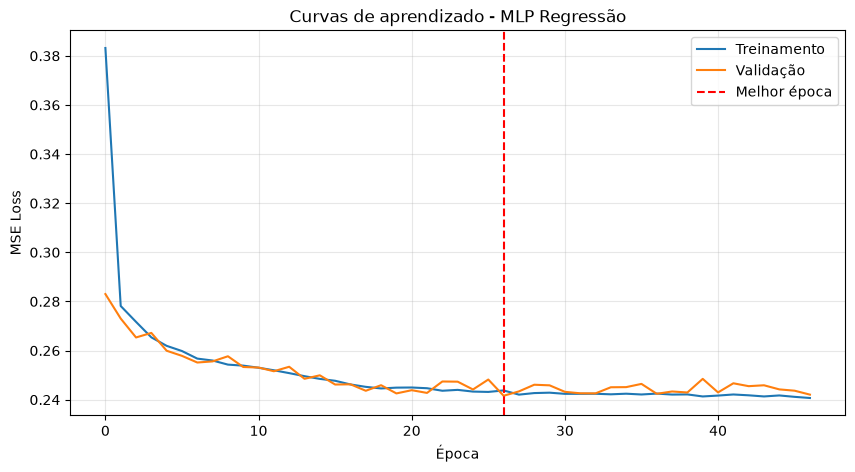

In [10]:
# Visualização das curvas de aprendizado (perda de treino vs validação) com destaque da melhor época

history = training_result["history"]

plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Treinamento")
plt.plot(history["val_loss"], label="Validação")

plt.axvline(
    x=training_result["best_epoch"] - 1,
    color="red",
    linestyle="--",
    label="Melhor época"
)

plt.xlabel("Época")
plt.ylabel("MSE Loss")
plt.title("Curvas de aprendizado - MLP Regressão")
plt.legend()
plt.grid(alpha=0.3)

plt.show()